# Toprak Tane Boyutu Dağılımı Tahmini - Soil Grain Size

Bu çalışmada Kaggle'daki Predicting Soil Grain Size Distributions from Images yarışmasını çözüyoruz. Bir toprak numunesinin yüzey fotoğraflarından, numunenin kümülatif tane boyutu eğrisini tahmin edeceğiz. Hata, tahmin eğrisi ile gerçek eğri arasındaki log ölçekli alan olan EMD ile ölçülüyor, düşük olan iyi.

Elimizde sadece 24 eğitim numunesi var, her numunenin birden fazla fotoğrafı var. Bu kadar az veriyle sinir ağı eğitmek yerine fotoğraflardan fiziksel anlamı olan özellikler çıkarıp (renk, doku, granülometri) basit modeller kullanacağız. Piksel boyutunu gerçek milimetreye çevirmek için kameraların `ppm` (piksel/mm) değerlerini kullanıyoruz.


In [1]:
import pandas as pd
import numpy as np
import glob, os, re, cv2

In [2]:
etiket=pd.read_csv('Training_labels_updated.csv')
ppm=pd.read_csv('ppm_updated.csv')
ornek=pd.read_csv('sample_submission.csv')

In [3]:
etiket.shape, ornek.shape

((24, 12), (10, 12))

In [4]:
ppm

,phone,camera,width,height,ppm
0,iPhone 14,iPhone 14,4032,3024,13.942
1,iPhone 16,iPhone 16,5712,4284,19.525
2,Motorola Edge,motorola edge 20,4000,1800,11.492
3,Motorola Edge 60 Fusion,Motorola Edge 60 fusion,4096,2304,12.465
4,Samsung A52,SM-A525F,9248,6936,26.330


In [5]:
etiket.round(1)

,sample_id,0.002,0.0063,0.02,0.063,0.2,0.63,2,6.3,20,63,200
0,F827,9.5,19.4,47.6,89.6,99.9,100.0,100.0,100.0,100.0,100.0,100.0
1,G190,5.2,10.2,23.8,50.3,75.8,85.7,91.0,94.9,98.6,100.0,100.0
2,H030,6.8,10.9,19.1,37.3,66.8,96.5,98.0,99.6,100.0,100.0,100.0
3,H037,0.9,6.4,16.3,27.8,34.7,46.4,62.7,79.1,89.8,100.0,100.0
4,H038,1.8,5.1,10.6,18.3,24.6,35.1,47.2,63.4,81.1,95.7,100.0
5,H126,6.3,12.6,32.5,68.4,84.6,89.5,94.8,99.5,100.0,100.0,100.0
6,H181,0.0,0.0,0.0,4.3,7.8,17.5,37.4,71.2,95.6,100.0,100.0
7,H183,0.0,0.0,0.0,4.9,8.1,14.4,32.3,65.7,95.8,100.0,100.0
8,H366,1.0,2.1,5.0,9.5,13.7,20.3,32.8,55.4,86.2,100.0,100.0
9,H367,0.8,1.9,4.1,7.5,11.1,17.4,30.4,56.1,85.8,100.0,100.0


In [43]:
sutunlar=etiket.columns[1:].tolist()  
x=np.array([float(c) for c in sutunlar])
Y=etiket[sutunlar].values

In [7]:
uzanti=('.jpg','.jpeg','.png')
egitim_dosya=[f for f in glob.glob('Training*/**/*',recursive=True) if f.lower().endswith(uzanti)]
test_dosya=[f for f in glob.glob('Test*/**/*',recursive=True) if f.lower().endswith(uzanti)]
len(egitim_dosya), len(test_dosya)

(127, 35)

In [8]:
egitim_dosya[:3]

['Training-All_Photos_updated\\Training-All_Photos_updated\\Motorola_Edge_60_fusion_H374_01.jpg',
 'Training-All_Photos_updated\\Training-All_Photos_updated\\Motorola_Edge_60_fusion_H374_02.jpg',
 'Training-All_Photos_updated\\Training-All_Photos_updated\\Motorola_Edge_60_fusion_H374_03.jpg']

In [9]:
def numune_bul(dosya,idler):
    ad=os.path.basename(dosya)
    for i in idler:
        k=i.replace(' ','_')
        if re.search(re.escape(k)+r'(?=[_.])',ad,re.IGNORECASE):
            return i
    return None

In [10]:
def kamera_bul(dosya):
    ad=os.path.basename(dosya).lower()
    bulunan=None
    for _,s in ppm.iterrows():
        k=s['phone'].lower().replace(' ','_')
        if ad.startswith(k) and (bulunan is None or len(k)>len(bulunan['phone'])):
            bulunan=s
    return bulunan

In [11]:
sorunlu=[d for d in egitim_dosya+test_dosya if numune_bul(d,etiket.sample_id.tolist()+ornek.sample_id.tolist()) is None or kamera_bul(d) is None]
len(sorunlu), sorunlu[:5]

(35,
 ['Test_All_Photos\\Test_All_Photos\\iPhone14_HPC_Audorfring (1).JPG',
  'Test_All_Photos\\Test_All_Photos\\iPhone14_HPC_Audorfring (2).JPG',
  'Test_All_Photos\\Test_All_Photos\\iPhone14_HPC_Audorfring (3).JPG',
  'Test_All_Photos\\Test_All_Photos\\iPhone14_HPC_Audorfring (4).JPG',
  'Test_All_Photos\\Test_All_Photos\\iPhone14_HPC_Audorfring (5).JPG'])

In [42]:
pd.Series([numune_bul(d,etiket.sample_id.tolist()) for d in egitim_dosya]).value_counts()

H038    8
H371    7
H030    7
H183    7
H668    7
H405    6
H617    6
H037    6
H181    6
H372    6
H616    5
H615    5
H549    5
H493    5
H368    5
F827    5
G190    5
H516    4
H367    4
H366    4
H126    4
H666    4
H374    3
H637    3
Name: count, dtype: int64

(np.float64(-0.5), np.float64(2303.5), np.float64(4095.5), np.float64(-0.5))

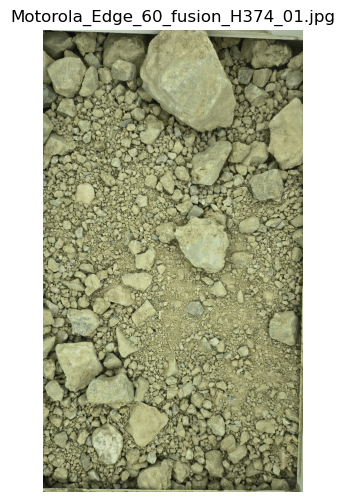

In [13]:
import matplotlib.pyplot as plt
img=cv2.imread(egitim_dosya[0])
plt.figure(figsize=(6,6))
plt.imshow(cv2.cvtColor(img,cv2.COLOR_BGR2RGB))
plt.title(os.path.basename(egitim_dosya[0]))
plt.axis('off')

Text(0.5, 1.0, '24 eğitim numunesinin eğrileri')

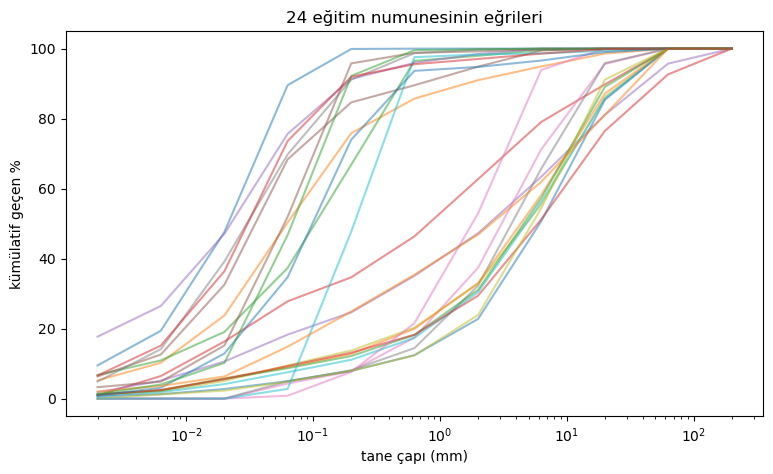

In [14]:
plt.figure(figsize=(9,5))
for i in range(len(Y)):
    plt.plot(x,Y[i],alpha=.5)
plt.xscale('log')
plt.xlabel('tane çapı (mm)')
plt.ylabel('kümülatif geçen %')
plt.title('24 eğitim numunesinin eğrileri')

In [15]:
w=np.diff(np.log10(x))  # 10 aralığın log10 genişliği (toplamı 5)
def emd(F,Fh):
    return float((np.abs(F[:10]-Fh[:10])*w).sum())

In [16]:
def duzelt(P):
    # kurallar: 0-100 arası, soldan sağa azalmayan, son sütun tam 100
    P=np.clip(P,0,100)
    P=np.maximum.accumulate(P,axis=1)
    P[:,-1]=100
    return P

In [17]:
# referans: her numune için diğer 23 numunenin ortalama eğrisini tahmin et
ref=[emd(Y[i],np.delete(Y,i,axis=0).mean(axis=0)) for i in range(len(Y))]
np.mean(ref)

np.float64(89.88886659893313)

In [18]:
# sample_submission'daki yer tutucu (hepsi 0) ne kadar kötü?
np.mean([emd(Y[i],np.zeros(11)) for i in range(len(Y))])

np.float64(246.44207989718885)

In [20]:
from ozellik import ozellik_cikar, ozellik_isimleri, etkin_ppm

In [21]:
def tablo_olustur(dosyalar,idler):
    satir=[]
    for d in dosyalar:
        numune=numune_bul(d,idler)
        kam=kamera_bul(d)
        if numune is None or kam is None:
            print('atlandı:',d)
            continue
        im=cv2.imread(d)
        H,W=im.shape[:2]
        p=etkin_ppm(kam['ppm'],kam['width'],kam['height'],W,H)
        satir.append([numune]+list(ozellik_cikar(im,p)))
    return pd.DataFrame(satir,columns=['numune']+ozellik_isimleri())

In [22]:
df_egitim=tablo_olustur(egitim_dosya,etiket.sample_id.tolist())  # birkaç dakika sürebilir

In [23]:
df_egitim.shape

(127, 27)

In [44]:
ozet=df_egitim.groupby('numune').mean()
X=ozet.loc[etiket.sample_id].values
X.shape

(24, 26)

In [25]:
# numara farkı 10'dan az olan aynı harfli numuneleri aynı gruba koy
idler=etiket.sample_id.tolist()
grup=list(range(len(idler)))
def kok(a):
    while grup[a]!=a:
        a=grup[a]
    return a
for i in range(len(idler)):
    for j in range(i):
        if idler[i][0]==idler[j][0] and abs(int(idler[i][1:])-int(idler[j][1:]))<=10:
            grup[kok(i)]=kok(j)
gruplar=np.array([kok(i) for i in range(len(idler))])
len(set(gruplar))

13

In [26]:
from sklearn.model_selection import LeaveOneGroupOut
def cv_skor(model_fn,gruplar):
    skorlar=[]
    for a,b in LeaveOneGroupOut().split(X,Y,gruplar):
        m=model_fn().fit(X[a],Y[a])
        P=duzelt(m.predict(X[b]))
        skorlar+=[emd(Y[k],P[j]) for j,k in enumerate(b)]
    return np.mean(skorlar)

In [27]:
from sklearn.dummy import DummyRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor

In [28]:
modeller={
 'Ortalama eğri (referans)':lambda: DummyRegressor(strategy='mean'),
 'Ridge alpha=10':lambda: make_pipeline(StandardScaler(),Ridge(alpha=10)),
 'Ridge alpha=100':lambda: make_pipeline(StandardScaler(),Ridge(alpha=100)),
 'Ridge alpha=1000':lambda: make_pipeline(StandardScaler(),Ridge(alpha=1000)),
 'kNN (k=3)':lambda: make_pipeline(StandardScaler(),KNeighborsRegressor(n_neighbors=3,weights='distance')),
 'Random Forest':lambda: RandomForestRegressor(n_estimators=300,min_samples_leaf=2,random_state=42)}

In [29]:
tek=np.arange(len(Y))  # her numune kendi grubu
karsilastirma=pd.DataFrame({'model':list(modeller),
    'emd_tek_tek':[cv_skor(f,tek) for f in modeller.values()],
    'emd_gruplu':[cv_skor(f,gruplar) for f in modeller.values()]})
karsilastirma.round(2)

,model,emd_tek_tek,emd_gruplu
0,Ortalama eğri (referans),89.89,96.54
1,Ridge alpha=10,45.51,48.55
2,Ridge alpha=100,50.66,57.26
3,Ridge alpha=1000,77.32,84.71
4,kNN (k=3),42.87,52.75
5,Random Forest,33.53,40.38


In [30]:
en_iyi=karsilastirma.loc[karsilastirma['emd_gruplu'].idxmin(),'model']  # gruplu skora göre seç
en_iyi

'Random Forest'

In [31]:
model=modeller[en_iyi]()
model.fit(X,Y)

,n_estimators,300
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,2
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [32]:
df_test=tablo_olustur(test_dosya,ornek.sample_id.tolist())
ozet_test=df_test.groupby('numune').mean().reindex(ornek.sample_id)
ozet_test.isnull().any(axis=1).sum()  # fotoğrafı olmayan test numunesi sayısı

atlandı: Test_All_Photos\Test_All_Photos\iPhone14_HPC_Audorfring (1).JPG
atlandı: Test_All_Photos\Test_All_Photos\iPhone14_HPC_Audorfring (2).JPG
atlandı: Test_All_Photos\Test_All_Photos\iPhone14_HPC_Audorfring (3).JPG
atlandı: Test_All_Photos\Test_All_Photos\iPhone14_HPC_Audorfring (4).JPG
atlandı: Test_All_Photos\Test_All_Photos\iPhone14_HPC_Audorfring (5).JPG
atlandı: Test_All_Photos\Test_All_Photos\iPhone14_HPC_Münster_BS6_9,0-10m (1).JPG
atlandı: Test_All_Photos\Test_All_Photos\iPhone14_HPC_Münster_BS6_9,0-10m (2).JPG
atlandı: Test_All_Photos\Test_All_Photos\iPhone14_HPC_Münster_BS6_9,0-10m (3).JPG
atlandı: Test_All_Photos\Test_All_Photos\iPhone14_HPC_Münster_BS6_9,0-10m (4).JPG
atlandı: Test_All_Photos\Test_All_Photos\iPhone14_HPC_Münster_BS6_9,0-10m (5).JPG
atlandı: Test_All_Photos\Test_All_Photos\iPhone14_HPC_Testfeld Lidl WHV (1).JPG
atlandı: Test_All_Photos\Test_All_Photos\iPhone14_HPC_Testfeld Lidl WHV (2).JPG
atlandı: Test_All_Photos\Test_All_Photos\iPhone14_HPC_Testfeld Li

np.int64(10)

In [33]:
Xt=ozet_test.fillna(pd.Series(X.mean(axis=0),index=ozet_test.columns)).values  # eksik olursa ortalama özellik

C:\Users\Sıla\AppData\Local\Temp\ipykernel_13240\1338451972.py:1: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  Xt=ozet_test.fillna(pd.Series(X.mean(axis=0),index=ozet_test.columns)).values  # eksik olursa ortalama özellik


In [34]:
tahmin=duzelt(model.predict(Xt))
tahmin=np.round(tahmin,4)

In [35]:
sonuc=pd.DataFrame(tahmin,columns=ornek.columns[1:])
sonuc.insert(0,'sample_id',ornek.sample_id.values)
sonuc.round(1)

,sample_id,0.002,0.0063,0.02,0.063,0.2,0.63,2,6.3,20,63,200
0,HPC_Airbus BS6-3,1.3,3.2,7.2,14.8,23.5,34.2,48.9,71.4,90.1,99.1,100.0
1,HPC_Audorfring,1.3,3.2,7.2,14.8,23.5,34.2,48.9,71.4,90.1,99.1,100.0
2,HPC_Muenster_BS6_9_0-10m,1.3,3.2,7.2,14.8,23.5,34.2,48.9,71.4,90.1,99.1,100.0
3,HPC_Airbus BS10-4bis7,1.3,3.2,7.2,14.8,23.5,34.2,48.9,71.4,90.1,99.1,100.0
4,HPC_Airbus BS12-5bis8,1.3,3.2,7.2,14.8,23.5,34.2,48.9,71.4,90.1,99.1,100.0
5,HPC_Kleinkummerfeld 2-2,1.3,3.2,7.2,14.8,23.5,34.2,48.9,71.4,90.1,99.1,100.0
6,HPC_Kleinkummerfeld 2-3,1.3,3.2,7.2,14.8,23.5,34.2,48.9,71.4,90.1,99.1,100.0
7,HPC_Kleinkummerfeld 9-4,1.3,3.2,7.2,14.8,23.5,34.2,48.9,71.4,90.1,99.1,100.0
8,HPC_Kleinkummerfeld 18-3,1.3,3.2,7.2,14.8,23.5,34.2,48.9,71.4,90.1,99.1,100.0
9,HPC_Testfeld Lidl WHV,1.3,3.2,7.2,14.8,23.5,34.2,48.9,71.4,90.1,99.1,100.0


In [36]:
def kontrol(s):
    assert list(s.columns)==list(ornek.columns), 'sütunlar farklı'
    assert (s.sample_id.values==ornek.sample_id.values).all(), 'sample_id farklı'
    v=s.iloc[:,1:].values.astype(float)
    assert v.min()>=0 and v.max()<=100, 'aralık dışı'
    assert (np.diff(v,axis=1)>=0).all(), 'azalan değer var'
    assert (v[:,-1]==100).all(), 'son sütun 100 değil'
    print('submission kurallara uygun')
kontrol(sonuc)

submission kurallara uygun


In [37]:
sonuc.to_csv('sonuc1.csv',index=False)

In [38]:
import pickle

In [39]:
pickle.dump(model,open('toprak.pkl','wb'))

In [40]:
kmodel=pickle.load(open('toprak.pkl','rb'))
kmodel.predict(X[:1]).round(1)  # ilk numunenin tahmin eğrisi

array([[  8.7,  16.2,  36.4,  69.5,  89.4,  95.2,  97.1,  98.6,  99.5,
        100. , 100. ]])

In [41]:
print(f'En iyi model: {en_iyi}')
print(f'Gruplu EMD: {karsilastirma.emd_gruplu.min():.1f} (ortalama eğri referansı: {karsilastirma.emd_gruplu.iloc[0]:.1f})')

En iyi model: Random Forest
Gruplu EMD: 40.4 (ortalama eğri referansı: 96.5)


### Sonuç

Bu çalışmada toprak yüzeyi fotoğraflarından tane boyutu eğrisini tahmin ettik. Veri çok küçük olduğu için (24 numune) sinir ağı yerine, fotoğraflardan milimetre ölçeğinde çıkardığımız renk, doku ve granülometri özelliklerini kullandık ve numune başına ortalamasını aldık.

